# 08 — Sensitivity of the rankings to the freshness cutoff

The main analysis keeps only players whose market value was updated in the last **365 days**. That cutoff is a choice, so this notebook checks whether the over/undervalued rankings change if we use **90, 180 or 540 days** instead.

Method:
1. Build the same dataset as in 02–07 for each cutoff (same pipeline from `src/features.py`, same features, 300-minute filter).
2. Get out-of-fold residuals for every player with the final model (tuned Gradient Boosting, parameters from `app/metrics.json`).
3. Compare each cutoff with 365 days **only on players that appear in both datasets**: Spearman rank correlation of residuals and overlap of the top-20 lists.
4. Compare with a **noise floor**: the 365-day data run again with a different CV seed. Differences smaller than this are just randomness of the cross-validation split.

In [1]:
import sys, json
sys.path.append("..")
import pandas as pd
import numpy as np
from scipy.stats import spearmanr
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.ensemble import GradientBoostingRegressor
from src.features import main_league_tier, filter_before_valuation, recent_window, per90
import matplotlib.pyplot as plt

pv = pd.read_csv("../data/player_valuations.csv", parse_dates=["date"])
players = pd.read_csv("../data/players.csv", parse_dates=["date_of_birth"])
appearances = pd.read_csv("../data/appearances.csv", parse_dates=["date"])
competitions = pd.read_csv("../data/competitions.csv")
max_date = pv["date"].max()
gb_params = json.load(open("../app/metrics.json"))["best_params"]

In [2]:
FEATURES = ["age", "age_squared", "total_minutes", "recent_goals_per_90", "recent_assists_per_90", "recent_minutes", "league_tier", "league_tier_missing", "position"]

def build_dataset(cutoff_days):
    cur = pv.sort_values("date").groupby("player_id").tail(1)
    cur = cur.rename(columns={"market_value_in_eur": "current_value", "date": "current_date"})
    cur = cur[(max_date - cur["current_date"]).dt.days <= cutoff_days][["player_id", "current_value", "current_date"]]
    apps = filter_before_valuation(appearances, cur)
    total = apps.groupby("player_id")["minutes_played"].sum().rename("total_minutes").reset_index()
    recent = recent_window(apps, days=365)
    rs = recent.groupby("player_id").agg(g=("goals", "sum"), a=("assists", "sum"), recent_minutes=("minutes_played", "sum")).reset_index()
    rs["recent_goals_per_90"] = per90(rs["g"], rs["recent_minutes"])
    rs["recent_assists_per_90"] = per90(rs["a"], rs["recent_minutes"])
    tiers = main_league_tier(recent, competitions)
    
    df = cur.merge(total, on="player_id").merge(players[["player_id", "date_of_birth", "position"]], on="player_id")
    df = df.merge(rs[["player_id", "recent_goals_per_90", "recent_assists_per_90", "recent_minutes"]], on="player_id", how="left")
    df = df.merge(tiers[["player_id", "league_tier"]], on="player_id", how="left")
    df["age"] = (df["current_date"] - df["date_of_birth"]).dt.days / 365.25
    df = df.dropna(subset=["age"])
    df = df[df["total_minutes"] >= 300].copy()
    for c in ["recent_goals_per_90", "recent_assists_per_90", "recent_minutes"]:
        df[c] = df[c].fillna(0)
    df["league_tier_missing"] = df["league_tier"].isna().astype(int)
    df["league_tier"] = df["league_tier"].fillna(1)
    df["age_squared"] = df["age"] ** 2
    df["log_value"] = np.log1p(df["current_value"])
    return df.reset_index(drop=True)

datasets = {c: build_dataset(c) for c in [90, 180, 365, 540]}
print({c: len(d) for c, d in datasets.items()})

{90: 4506, 180: 4733, 365: 4816, 540: 4837}


Dataset sizes barely change (4,506 → 4,837 players), because Transfermarkt updates most players in batches within a few months.

In [3]:
def oof_residuals(df, seed=42):
    X = pd.get_dummies(df[FEATURES], columns=['position'], drop_first=True)
    model = GradientBoostingRegressor(**gb_params, random_state=seed)
    preds = cross_val_predict(model, X, df["log_value"], cv=KFold(n_splits=5, shuffle=True, random_state=seed), n_jobs=-1)
    return pd.Series(df["log_value"].values - preds, index=df["player_id"])

In [4]:
def compare(a, b, n=20):
    common = a.index.intersection(b.index)
    a, b =a[common], b[common]
    return {"common_players": len(common), "spearman": round(spearmanr(a, b).correlation, 3), f"top{n}_under_overlap": len(set(a.nsmallest(n).index) & set(b.nsmallest(n).index)) / n, f"top{n}_over_overlap": len(set(a.nlargest(n).index) & set(b.nlargest(n).index)) / n}

In [5]:
res = {c: oof_residuals(d) for c, d in datasets.items()}
noise = oof_residuals(datasets[365], seed=7)

rows = [{"comparison": f"{c} vs 365", **compare(res[c], res[365])} for c in [90, 180, 540]]
rows.append({"comparison": "365 vs 365 (other seed) = noise floor", **compare(res[365], noise)})
table = pd.DataFrame(rows)
table

,comparison,common_players,spearman,top20_under_overlap,top20_over_overlap
0,90 vs 365,4506,0.975,0.80,0.80
1,180 vs 365,4733,0.978,0.70,0.80
2,540 vs 365,4816,0.980,0.90,0.85
3,365 vs 365 (other seed) = noise floor,4816,0.979,0.85,0.80


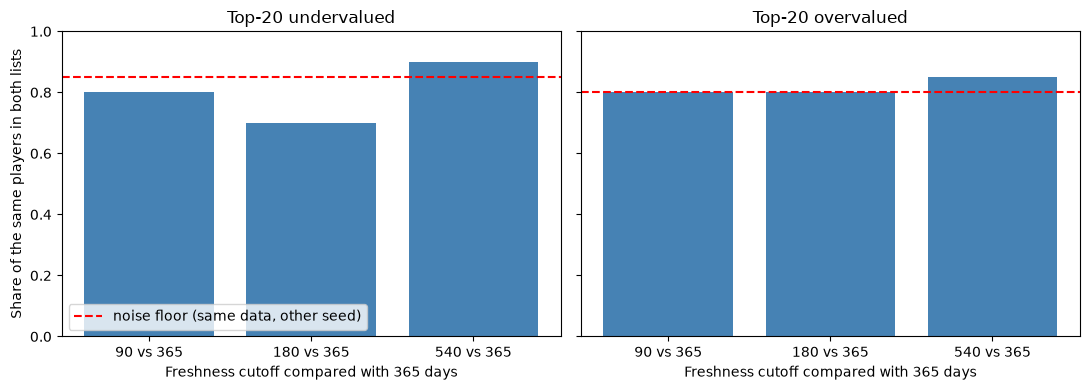

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
labels = ["90 vs 365", "180 vs 365", "540 vs 365"]
for ax, col, title in zip(axes, ["top20_under_overlap", "top20_over_overlap"], ["Top-20 undervalued", "Top-20 overvalued"]):
    ax.bar(labels, table[col][:3], color="steelblue")
    ax.axhline(table[col].iloc[3], color="red", linestyle="--", label="noise floor (same data, other seed)")
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Freshness cutoff compared with 365 days")
axes[0].set_ylabel("Share of the same players in both lists")
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

## Why the old version of this notebook was wrong

The first version trained one model per cutoff on a random 80% and built the top-20 lists only from its **own random 20% test set**. Different cutoffs had different test sets, so the lists contained mostly different players and overlapped only 10–25%, even though the model behaved the same. The low overlap came from the method, not from the cutoff.

## Conclusion

The freshness cutoff barely changes the rankings. The Spearman correlation of residuals with the 365-day version is 0.975–0.980 for every cutoff, the same as simply re-running the 365-day model with a different CV seed (0.979). Top-20 overlaps (0.70–0.90) are also at the level of this noise floor (0.80–0.85). The 365-day cutoff is therefore a safe choice, and the remaining differences in the top lists are cross-validation noise.